In [58]:
# discretize state space into SOFA and AL bins
import numpy as np
import pandas as pd
import math  


import matplotlib.pyplot as plt

In [56]:
Sepsis_data = pd.read_csv("../data/discretised_input_data.csv")
print(len(Sepsis_data))
# take patients 
sofa_bins = 25 # 0 - 24 

lactate_bins = 20 # choose 20 first 

278682


/Users/ongyichong/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:5: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  """


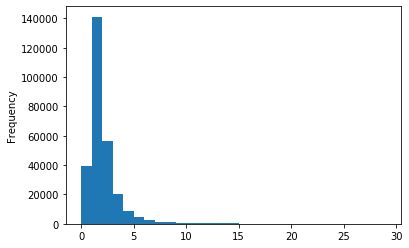

In [31]:
lactate_df = Sepsis_data['Arterial_lactate']
lactate_bin = [i for i in range(30)]
#bin_float_range = [i for i in np.arange(0, 30, 0.5)]
lactate_df.plot(kind='hist', bins = lactate_bin)
lactate_df['binned'] = pd.cut(lactate_df, bins=lactate_bin)




In [32]:
lactate_df['binned']

0         (0, 1]
1         (1, 2]
2         (0, 1]
3         (0, 1]
4         (0, 1]
           ...  
278677    (2, 3]
278678    (0, 1]
278679    (1, 2]
278680    (1, 2]
278681    (1, 2]
Name: Arterial_lactate, Length: 278682, dtype: category
Categories (29, interval[int64]): [(0, 1] < (1, 2] < (2, 3] < (3, 4] ... (25, 26] < (26, 27] < (27, 28] < (28, 29]]

In [33]:
lactate_df['binned'].value_counts()

(1, 2]      134359
(0, 1]       54035
(2, 3]       50882
(3, 4]       19291
(4, 5]        7869
(5, 6]        4373
(6, 7]        2508
(7, 8]        1408
(8, 9]        1025
(9, 10]        745
(10, 11]       497
(11, 12]       389
(12, 13]       348
(13, 14]       258
(14, 15]       215
(15, 16]       133
(16, 17]        63
(17, 18]        49
(19, 20]        49
(18, 19]        46
(20, 21]        25
(23, 24]        23
(21, 22]        21
(25, 26]        21
(24, 25]        17
(22, 23]        10
(27, 28]         1
(26, 27]         1
(28, 29]         1
Name: Arterial_lactate, dtype: int64

In [37]:
# bin the 2 features accordingly -> 750 state MDP 
tupleToNumericStates = {}
numericStatesToTuple = {}
count = 0
for i in range(sofa_bins):
    for j in range(len(lactate_bin)):
        tupleToNumericStates[(i,j)] = count
        numericStatesToTuple[count] = (i,j)
        count += 1


In [42]:
# convert sepsis data to states
tupleToNumericStates[(5,10)]
numericStatesToTuple[749]

(24, 29)

In [59]:
# convert continuous variables to discrete states. Retain icu stay id, discretize actions. 
# add to the current sepsis data
states = []
for i in range(len(Sepsis_data)):
    row = Sepsis_data.iloc[i]
    sofa_score = row['SOFA']
    al_score = math.floor(row['Arterial_lactate'])
    state = tupleToNumericStates[(sofa_score, al_score)]
    states.append(state)
    
Sepsis_data['discrete_states'] = states

In [61]:
Sepsis_data['discrete_states'].value_counts() # only 519 / 750 states visited

151    17005
121    16674
181    16646
211    14956
91     13058
       ...  
537        1
684        1
593        1
173        1
630        1
Name: discrete_states, Length: 519, dtype: int64

In [73]:
# build transition probability matrix

# build actions
actions = {}
count = 0
for i in range(5):
    for j in range(5):
        actions[(i,j)] = count
        count += 1

        
sepsis_actions=[]
for i in range(len(Sepsis_data)):
    row = Sepsis_data.iloc[i]
    iv_input = row['iv_input']
    vaso_input = row['vaso_input']
    action = actions[(iv_input, vaso_input)]
    sepsis_actions.append(action)

Sepsis_data['actions'] = sepsis_actions
        

In [87]:
# build transition matrix
T = np.zeros((750, 25, 750))

for i in range(len(Sepsis_data) - 1):
    icu_id = Sepsis_data.iloc[i]['icustayid']
    icu_id_next = Sepsis_data.iloc[i+1]['icustayid']
    
    if (icu_id == icu_id_next):
        curr_state = int(Sepsis_data.iloc[i]['discrete_states'])
        next_state = int(Sepsis_data.iloc[i+1]['discrete_states'])
        curr_action = int(Sepsis_data.iloc[i]['actions'])

        T[curr_state][curr_action][next_state] += 1


# calculate probability density estimation
for i in range(750):
    for j in range(25):
        temp_sum = np.sum(T[i][j][:])
        T[i][j][:] = T[i][j][:] / temp_sum

/Users/ongyichong/anaconda3/lib/python3.6/site-packages/ipykernel_launcher.py:20: RuntimeWarning: invalid value encountered in true_divide


In [90]:
T[np.isnan(T)] = 0

In [92]:
# feature matrix. 6 features for SOFA and arterial lactate. SOFA 1 for increase, 1 for maintain, 1 for decrease then AL
# Define as S,A,S' again from data

F = np.zeros((750, 25, 750, 6))
for i in range(len(Sepsis_data) - 1):
    icu_id = Sepsis_data.iloc[i]['icustayid']
    icu_id_next = Sepsis_data.iloc[i+1]['icustayid']
    
    if (icu_id == icu_id_next):
        curr_state = int(Sepsis_data.iloc[i]['discrete_states'])
        next_state = int(Sepsis_data.iloc[i+1]['discrete_states'])
        curr_action = int(Sepsis_data.iloc[i]['actions'])
        
        # convert next state to actual SOFA and AL scores 
        curr_sofa, curr_al = numericStatesToTuple[curr_state]
        next_sofa, next_al = numericStatesToTuple[next_state]
        
        sofa_inc = 0
        sofa_maint = 0
        sofa_dec = 0
        
        al_inc = 0
        al_maint = 0
        al_dec = 0
        
        if (curr_sofa < next_sofa):
            sofa_inc = 1
        if (curr_sofa == next_sofa):
            sofa_maint = 1
        if (curr_sofa > next_sofa):
            sofa_dec = 1
            
        if (curr_al < next_al):
            al_inc = 1
        if (curr_al == next_al):
            al_maint = 1
        if (curr_al > next_al):
            al_dec = 1
            
        f = [sofa_inc, sofa_maint, sofa_dec, al_inc, al_maint, al_dec]
        F[curr_state][curr_action][next_state] = f


In [326]:
# build trajectory demonstration data
no_trajs = len(Sepsis_data['icustayid'].unique())
max_len = 20
demonstrations_states = np.zeros((no_trajs, max_len + 1)) # store trajectory and policy
demonstrations_actions = np.zeros((no_trajs, max_len))
demonstrations_states.fill(-1)
demonstrations_actions.fill(-1)

In [327]:
# trajectory contains state change + icustayid at the end ( idx = 20)
trajectory = []
trajectory_actions = []
count = 0
for i in range(len(Sepsis_data) - 1):
    curr_icustayid = Sepsis_data.iloc[i]['icustayid']
    next_icustayid = Sepsis_data.iloc[i+1]['icustayid']
    
    curr_state = Sepsis_data.iloc[i]['discrete_states']
    curr_action = Sepsis_data.iloc[i]['actions']
    

    trajectory.append(curr_state)
    trajectory_actions.append(curr_action)
    

    if (curr_icustayid != next_icustayid):   
        for i in range(max_len - len(trajectory)):
            trajectory.append(-1)
            trajectory_actions.append(-1)
        #print(trajectory)
        trajectory.append(curr_icustayid)
        demonstrations_states[count] = trajectory
        demonstrations_actions[count] = trajectory_actions
        count += 1
        trajectory = []
        trajectory_actions = []

        
last_state = Sepsis_data.iloc[-1]['discrete_states']
last_action = Sepsis_data.iloc[-1]['actions']
trajectory.append(last_state)
trajectory_actions.append(last_action)
for i in range(max_len - len(trajectory)):
    trajectory.append(-1)
    trajectory_actions.append(-1)
    
trajectory.append(curr_icustayid)
demonstrations_states[count] = trajectory
demonstrations_actions[count] = trajectory_actions

In [329]:
# append last state

array([240., 211., 180., 180., 180., 180., 331.,  -1.,  -1.,  -1.,  -1.,
        -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.,   3.])

In [264]:
demonstration

[272.0,
 152.0,
 122.0,
 91.0,
 61.0,
 31.0,
 31.0,
 1.0,
 2.0,
 60.0,
 211.0,
 1.0,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 -1,
 1.0]

In [116]:
# value of last state if it is not connected to any other state is 0.
# V_pi(s) = T(s,a,s')[R(s,a,s') + gamma * V_pi(s')]. If last state not connected to any other states, then T(s,a,s')
# for all s' will be 0. Hence, V_pi(s) = 0

In [124]:
F[0][0][0]

array([0., 1., 0., 0., 1., 0.])

In [123]:
print(T[0][5])

[0.28176796 0.08287293 0.03314917 0.01657459 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.02762431 0.06077348 0.01657459 0.00552486 0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.00552486 0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.08839779 0.0441989  0.01657459 0.         0.         0.
 0.00552486 0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.         0.         0.         0.         0.         0.
 0.01104972 0.03867403 0.02209945 0.01104972 0.00552486 0.
 0.         0.         0.         0.         0.         

In [126]:
# save transition matrix, mdp.Features
import scipy.io
scipy.io.savemat('transitionSepsis.mat', mdict={"transMat" : T})
scipy.io.savemat('featuresSepsis.mat', mdict={"featureSepsis" : F})

In [328]:
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_states.mat', mdict={"demonstrations_states" : demonstrations_states})
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_actions.mat', mdict={"demonstrations_actions" : demonstrations_actions})

In [131]:
demonstrations[1][0]

array([10., 10., 10., 10.,  5.,  0.,  0., -1., -1., -1., -1., -1., -1.,
       -1., -1., -1., -1., -1., -1., -1.])

In [134]:
demonstrations

array([[[-1., -1.],
        [-1., -1.],
        [-1., -1.],
        ...,
        [-1., -1.],
        [-1., -1.],
        [-1., -1.]],

       [[-1., -1.],
        [-1., -1.],
        [-1., -1.],
        ...,
        [-1., -1.],
        [-1., -1.],
        [-1., -1.]],

       [[-1., -1.],
        [-1., -1.],
        [-1., -1.],
        ...,
        [-1., -1.],
        [-1., -1.],
        [-1., -1.]],

       ...,

       [[-1., -1.],
        [-1., -1.],
        [-1., -1.],
        ...,
        [-1., -1.],
        [-1., -1.],
        [-1., -1.]],

       [[-1., -1.],
        [-1., -1.],
        [-1., -1.],
        ...,
        [-1., -1.],
        [-1., -1.],
        [-1., -1.]],

       [[-1., -1.],
        [-1., -1.],
        [-1., -1.],
        ...,
        [-1., -1.],
        [-1., -1.],
        [-1., -1.]]])

In [146]:
demonstrations_states[0]

array([240., 211., 180., 180., 180., 180., 331.,  -1.,  -1.,  -1.,  -1.,
        -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.])

In [147]:
demonstrations_actions[0]

array([10., 10., 10., 10.,  5.,  0.,  0., -1., -1., -1., -1., -1., -1.,
       -1., -1., -1., -1., -1., -1., -1.])

In [149]:
# reshape transition matrix from T(S,A,S') to T(S',S,A)
T_reshape = np.zeros((750,750,25))

for s_ in range(750):
    for s in range(750):
        for a in range(25):
            # prob of taking action a at state s and transitioning to s_ 
            T_reshape[s_][s][a] = T[s][a][s_]

            
scipy.io.savemat('transitionSepsis_reshape.mat', mdict={"transMat_reshape" : T_reshape})

In [152]:
test = scipy.io.loadmat('test.mat')

In [154]:
test_struct = test['maxCl']

In [157]:
maxCl = test_struct[0,0]

In [160]:
print(maxCl['belongTo'])
print(maxCl['weight'])
print(maxCl['policy']) # -> policy here should be -1 from the actual.

[[1]
 [1]]
[[ 0.91501367]
 [ 0.92977707]
 [-0.68477384]
 [ 0.94118556]
 [ 0.9143339 ]
 [-0.0292487 ]]
[[12]
 [ 3]
 [ 3]
 [ 9]
 [25]
 [24]
 [16]
 [16]
 [11]
 [24]
 [16]
 [ 6]
 [ 6]
 [ 1]
 [ 1]
 [ 6]
 [11]
 [ 1]
 [21]
 [16]
 [ 6]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 6]
 [21]
 [21]
 [21]
 [ 1]
 [ 1]
 [21]
 [11]
 [16]
 [16]
 [ 6]
 [16]
 [16]
 [ 6]
 [21]
 [ 1]
 [ 1]
 [ 1]
 [16]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [21]
 [11]
 [11]
 [11]
 [11]
 [21]
 [11]
 [21]
 [11]
 [11]
 [ 6]
 [11]
 [11]
 [ 6]
 [ 1]
 [11]
 [ 1]
 [ 1]
 [ 1]
 [ 6]
 [21]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 6]
 [ 1]
 [ 1]
 [ 1]
 [16]
 [13]
 [18]
 [ 7]
 [18]
 [22]
 [12]
 [ 1]
 [12]
 [21]
 [11]
 [11]
 [ 6]
 [21]
 [11]
 [21]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [11]
 [ 1]
 [ 6]
 [ 1]
 [21]
 [ 1]
 [ 6]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [19]
 [10]
 [ 3]
 [13]
 [ 2]
 [12]
 [22]
 [22]
 [11]
 [25]
 [16]
 [21]
 [11]
 [ 1]
 [ 1]
 [11]
 [16]
 [22]
 [ 6]
 [11]
 [11]
 [ 6]
 [ 1]
 [21]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1]
 [ 1

In [163]:
demonstrations_states[0]

array([240., 211., 180., 180., 180., 180., 331.,  -1.,  -1.,  -1.,  -1.,
        -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.,  -1.])

In [268]:
traj_19_states = list(filter(lambda x: x[-2] == -1 and x[-3] != -1, demonstrations_states))
# trajectory of length 19 -> 526 clinical trajectories
# because x[-1] is the icustayid

In [269]:
traj_19_actions = list(filter(lambda x: x[-1] == -1 and x[-2] != -1, demonstrations_actions))

In [270]:
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_states_19.mat', mdict={"demonstrations_states_19" : traj_19_states})
scipy.io.savemat('../DPM_IRL/MDP/demonstrations_actions_19.mat', mdict={"demonstrations_actions_19" : traj_19_actions})

In [271]:
np.save('./dataSets/demonstrations_states_19.npy', traj_19_states)
np.save('./dataSets/demonstrations_actions_19.npy', traj_19_actions)

In [201]:
# construct 3D MDP features for faster evaluation
feature_reshape = np.reshape(F, (750*25*750, 6))
transition_reshape = np.reshape(T, (750*25*750, 1))
temp_matrix = np.multiply(feature_reshape, transition_reshape)
mdp_feature_reshape = np.reshape(temp_matrix, (750,25,750, 6))

In [217]:
reshaped_features = np.zeros((750, 25, 6)) # F
for s in range(750):
    for a in range(25):
        temp = mdp_feature_reshape[s][a][:] # 2D matrix
        temp_sum = np.sum(temp,axis=0)
        reshaped_features[s][a] = temp_sum
        
        

In [222]:
w = [0.5, 0.5, 0, 0.2, 0.1, 0]
r_s_a = np.sum(reshaped_features[0][0] * w)

In [227]:
r_s_a

0.6477611940298509

In [225]:
feat = np.zeros((1,6))
for s_ in range(750):
    feat += T[0][0][s_] * F[0][0][s_]

In [228]:
np.sum(feat * w)

0.6477611940298509

In [234]:
# save 3D features to use for r(s,a)
scipy.io.savemat('reshaped_features.mat', mdict={"reshaped_features" : reshaped_features})

In [324]:
feature_reshape[990]

array([1., 0., 0., 0., 1., 0.])

In [320]:
F[0][1][240]

array([1., 0., 0., 0., 1., 0.])

4740

array([[[[0.        , 0.33208955, 0.        , 0.        , 0.33208955,
          0.        ],
         [0.        , 0.10447761, 0.        , 0.10447761, 0.        ,
          0.        ],
         [0.        , 0.02238806, 0.        , 0.02238806, 0.        ,
          0.        ],
         ...,
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ]],

        [[0.        , 0.5       , 0.        , 0.        , 0.5       ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         ...,
         [0.        , 0.        , 0.        , 0.        , 0.        ,
          0.        ],
         [0.        , 0.        , 0.    